# Notebook 04: Customer Segmentation

## AI Revenue Optimization & Conversion Intelligence System for Nattoguard

This notebook focuses on grouping customer sessions into behavior-based segments using unsupervised machine learning.

Unlike conversion prediction, customer segmentation does not use the `Revenue` column as the target during training. Instead, the model groups customers based on similar behavior patterns such as product page visits, page duration, bounce rate, exit rate, and page value.

The purpose of this notebook is to identify meaningful customer groups that can later support personalized marketing actions, LLM-generated messages, and chatbot workflows.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_PATH = Path("../data/processed/online_shoppers_cleaned.csv")
FIGURES_PATH = Path("../outputs/figures")
MODEL_RESULTS_PATH = Path("../outputs/model_results")
CHATBOT_INPUTS_PATH = Path("../outputs/chatbot_inputs")
SLIDE_ASSETS_PATH = Path("../outputs/slide_assets")

FIGURES_PATH.mkdir(parents=True, exist_ok=True)
MODEL_RESULTS_PATH.mkdir(parents=True, exist_ok=True)
CHATBOT_INPUTS_PATH.mkdir(parents=True, exist_ok=True)
SLIDE_ASSETS_PATH.mkdir(parents=True, exist_ok=True)

print("Project paths prepared successfully.")

Project paths prepared successfully.


In [3]:
df = pd.read_csv(DATA_PATH)

print("Cleaned dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Cleaned dataset loaded successfully.
Shape: (12205, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
segmentation_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

X_segmentation = df[segmentation_features].copy()

print("Segmentation feature shape:", X_segmentation.shape)
X_segmentation.head()

Segmentation feature shape: (12205, 10)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_segmentation)

print("Features scaled successfully.")
print("Scaled data shape:", X_scaled.shape)

Features scaled successfully.
Scaled data shape: (12205, 10)


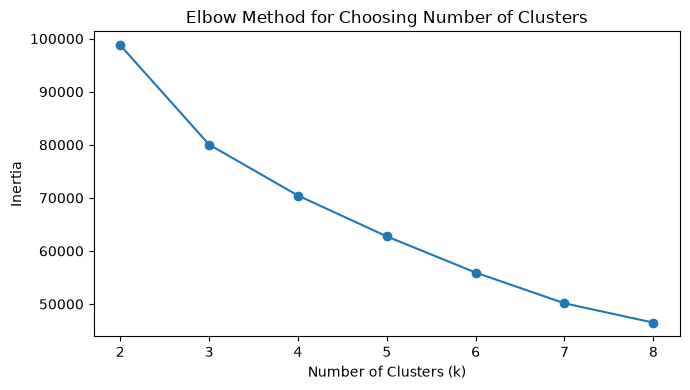

In [6]:
inertia_values = []

k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Choosing Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "elbow_method_customer_segmentation.png", dpi=300)
plt.show()

In [7]:
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)

silhouette_df = pd.DataFrame({
    "k": list(k_values),
    "silhouette_score": silhouette_scores
})

silhouette_df

,k,silhouette_score
0,2,0.434865
1,3,0.453442
2,4,0.423410
3,5,0.388044
4,6,0.396085
5,7,0.398524
6,8,0.363165


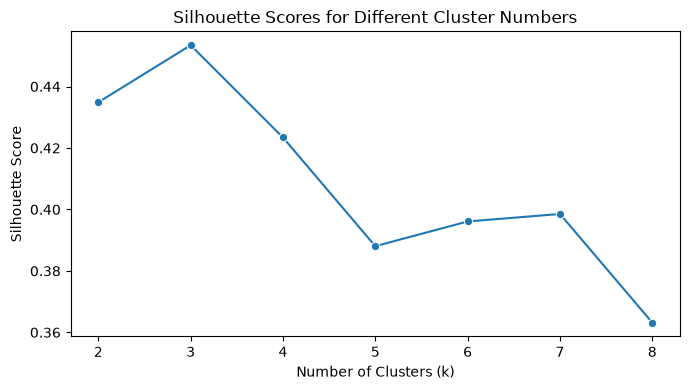

In [8]:
plt.figure(figsize=(7, 4))
sns.lineplot(data=silhouette_df, x="k", y="silhouette_score", marker="o")
plt.title("Silhouette Scores for Different Cluster Numbers")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "silhouette_scores_customer_segmentation.png", dpi=300)
plt.show()

In [9]:
FINAL_K = 3

kmeans_model = KMeans(n_clusters=FINAL_K, random_state=42, n_init=10)

df_segments = df.copy()
df_segments["customer_cluster"] = kmeans_model.fit_predict(X_scaled)

print("K-Means clustering completed.")
df_segments[["customer_cluster"]].head()

K-Means clustering completed.


,customer_cluster
0,0
1,1
2,0
3,0
4,1


In [10]:
cluster_distribution = df_segments["customer_cluster"].value_counts().sort_index()

cluster_distribution

customer_cluster
0     932
1    9647
2    1626
Name: count, dtype: int64

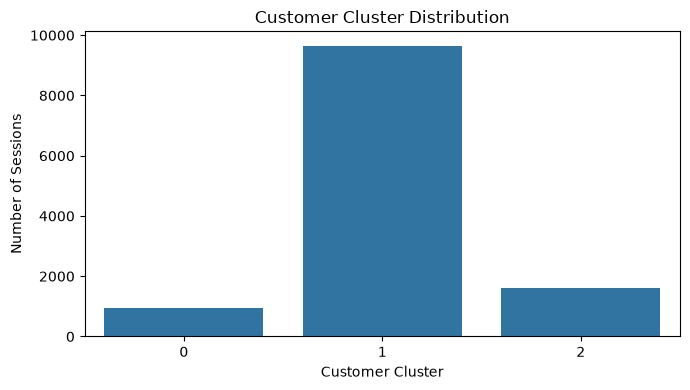

In [11]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_segments, x="customer_cluster")
plt.title("Customer Cluster Distribution")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "customer_cluster_distribution.png", dpi=300)
plt.show()

In [12]:
cluster_profile = df_segments.groupby("customer_cluster")[segmentation_features].mean().round(2)

cluster_profile

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
customer_cluster,,,,,,,,,,
0,0.05,1.60,0.02,0.10,3.36,65.80,0.16,0.18,0.00,0.12
1,1.71,51.22,0.22,8.21,23.90,874.41,0.01,0.03,5.89,0.06
2,7.38,308.03,2.52,212.64,96.83,3834.25,0.01,0.02,9.73,0.03


In [13]:
cluster_revenue_rate = df_segments.groupby("customer_cluster")["Revenue"].mean().round(4) * 100

cluster_revenue_rate = cluster_revenue_rate.rename("Revenue_Rate_Percentage")

cluster_summary = cluster_profile.copy()
cluster_summary["Revenue_Rate_Percentage"] = cluster_revenue_rate.round(2)
cluster_summary["Session_Count"] = df_segments["customer_cluster"].value_counts().sort_index()

cluster_summary

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Revenue_Rate_Percentage,Session_Count
customer_cluster,,,,,,,,,,,,
0,0.05,1.60,0.02,0.10,3.36,65.80,0.16,0.18,0.00,0.12,0.64,932
1,1.71,51.22,0.22,8.21,23.90,874.41,0.01,0.03,5.89,0.06,15.03,9647
2,7.38,308.03,2.52,212.64,96.83,3834.25,0.01,0.02,9.73,0.03,27.80,1626


In [14]:
cluster_summary.to_csv(MODEL_RESULTS_PATH / "customer_cluster_summary.csv")
cluster_summary.to_csv(SLIDE_ASSETS_PATH / "customer_cluster_summary.csv")

print("Cluster summary saved successfully.")

Cluster summary saved successfully.


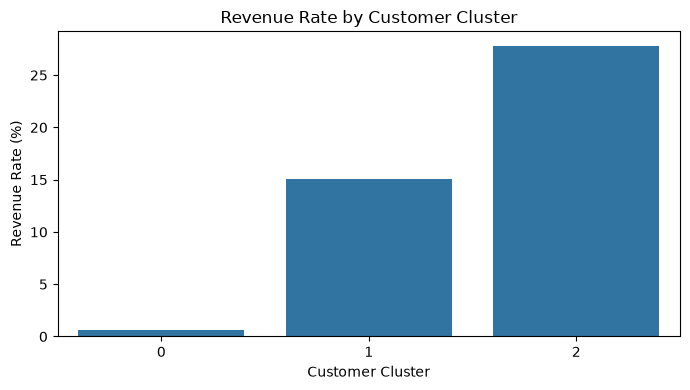

In [15]:
cluster_revenue_plot = cluster_summary.reset_index()

plt.figure(figsize=(7, 4))
sns.barplot(
    data=cluster_revenue_plot,
    x="customer_cluster",
    y="Revenue_Rate_Percentage"
)
plt.title("Revenue Rate by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Revenue Rate (%)")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "revenue_rate_by_customer_cluster.png", dpi=300)
plt.show()

In [22]:
# Rank clusters by revenue rate
cluster_rank = cluster_summary["Revenue_Rate_Percentage"].sort_values().index.tolist()

cluster_label_mapping = {
    cluster_rank[0]: "Low Engagement Browsers",
    cluster_rank[1]: "Moderate Interest Visitors",
    cluster_rank[2]: "High-Value Intent Users"
}

df_segments["behavior_segment"] = df_segments["customer_cluster"].map(cluster_label_mapping)

df_segments[["customer_cluster", "behavior_segment"]].head()

,customer_cluster,behavior_segment
0,0,Low Engagement Browsers
1,1,Moderate Interest Visitors
2,0,Low Engagement Browsers
3,0,Low Engagement Browsers
4,1,Moderate Interest Visitors


In [23]:
behavior_segment_distribution = df_segments["behavior_segment"].value_counts().reset_index()
behavior_segment_distribution.columns = ["Behavior Segment", "Count"]

behavior_segment_distribution

,Behavior Segment,Count
0,Moderate Interest Visitors,9647
1,High-Value Intent Users,1626
2,Low Engagement Browsers,932


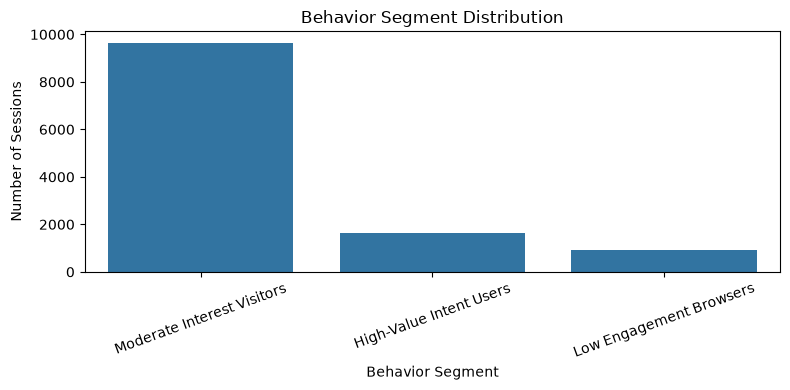

In [24]:
plt.figure(figsize=(8, 4))
sns.barplot(
    data=behavior_segment_distribution,
    x="Behavior Segment",
    y="Count"
)
plt.title("Behavior Segment Distribution")
plt.xlabel("Behavior Segment")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "behavior_segment_distribution.png", dpi=300)
plt.show()

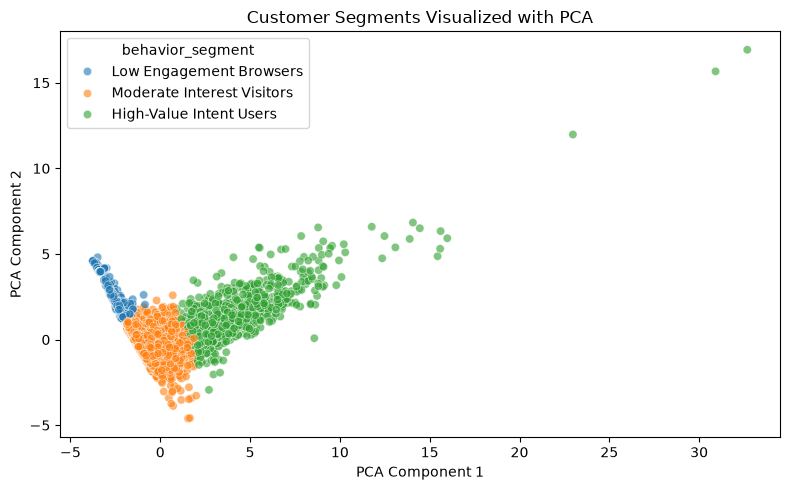

In [25]:
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "behavior_segment": df_segments["behavior_segment"]
})

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="behavior_segment",
    alpha=0.6
)
plt.title("Customer Segments Visualized with PCA")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "customer_segments_pca_visualization.png", dpi=300)
plt.show()

In [26]:
segment_strategy = pd.DataFrame([
    {
        "Behavior Segment": "Low Engagement Browsers",
        "Behavior Meaning": "Users show limited browsing activity and lower purchase behavior.",
        "Marketing Strategy": "Use awareness ads, educational content, and retargeting campaigns."
    },
    {
        "Behavior Segment": "Moderate Interest Visitors",
        "Behavior Meaning": "Users show some product interest but may need more information before purchasing.",
        "Marketing Strategy": "Send product education, benefit-focused emails, and FAQ-style content."
    },
    {
        "Behavior Segment": "High-Value Intent Users",
        "Behavior Meaning": "Users show stronger engagement and higher revenue potential.",
        "Marketing Strategy": "Send checkout reminders, limited-time offers, and personalized product messages."
    }
])

segment_strategy

,Behavior Segment,Behavior Meaning,Marketing Strategy
0,Low Engagement Browsers,Users show limited browsing activity and lower...,"Use awareness ads, educational content, and re..."
1,Moderate Interest Visitors,Users show some product interest but may need ...,"Send product education, benefit-focused emails..."
2,High-Value Intent Users,Users show stronger engagement and higher reve...,"Send checkout reminders, limited-time offers, ..."


In [27]:
segment_strategy.to_csv(SLIDE_ASSETS_PATH / "customer_segment_marketing_strategy.csv", index=False)
segment_strategy.to_csv(CHATBOT_INPUTS_PATH / "customer_segment_marketing_strategy.csv", index=False)

print("Segment marketing strategy saved successfully.")

Segment marketing strategy saved successfully.


In [29]:
segmented_output = df_segments.copy()

# Keep original row index as session_id for merging with prediction outputs
segmented_output.insert(0, "session_id", segmented_output.index)

segmented_output.to_csv(
    MODEL_RESULTS_PATH / "online_shoppers_customer_segments.csv",
    index=False
)

segmented_output[[
    "session_id",
    "customer_cluster",
    "behavior_segment",
    "Revenue"
]].to_csv(
    CHATBOT_INPUTS_PATH / "customer_behavior_segments.csv",
    index=False
)

print("Segmented customer data saved successfully.")

Segmented customer data saved successfully.


## Customer Segmentation Conclusion

In this notebook, K-Means clustering was used to group customer sessions based on behavioral patterns such as page visits, page duration, bounce rate, exit rate, and page value.

The clustering process produced three customer behavior segments:

- Low Engagement Browsers
- Moderate Interest Visitors
- High-Value Intent Users

These segments provide business-friendly customer groups that can support targeted marketing actions. For example, high-value intent users can receive checkout reminders or personalized offers, while moderate interest visitors can receive educational content about Nattoguard.

The segmentation output will later support the decision engine, LLM-generated marketing messages, and chatbot workflow.